# Lab 6: Wheat Seed Classification Using ANN

ML Laboratory experiment — Tanushri sapate (B-B3, Roll No. 44).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score, confusion_matrix, classification_report)
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
df=pd.read_csv("../data/seeds_new.csv")


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
Area,0
Perimeter,0
Compactness,0
Length of kernel,0
Width of kernel,0
Asymmetry coefficient,0
Length of kernel groove,0
"Class (1, 2, 3)",0


In [ ]:
df.shape

(210, 8)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Area                     210 non-null    float64
 1   Perimeter                210 non-null    float64
 2   Compactness              210 non-null    float64
 3   Length of kernel         210 non-null    float64
 4   Width of kernel          210 non-null    float64
 5   Asymmetry coefficient    210 non-null    float64
 6   Length of kernel groove  210 non-null    float64
 7   Class (1, 2, 3)          210 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 13.3 KB


In [ ]:
df=df.dropna(axis=1,how="all")

In [ ]:
df=df.loc[:,~df.columns.str.startswith("Unnamed")]

In [ ]:
df.head()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


In [ ]:
df.tail()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3
209,12.30,13.34,0.8684,5.243,2.974,5.637,5.063,3


In [ ]:
df.columns

Index(['Area', 'Perimeter', 'Compactness', 'Length of kernel',
       'Width of kernel', 'Asymmetry coefficient', 'Length of kernel groove',
       'Class (1, 2, 3)'],
      dtype='object')

In [ ]:
df.describe()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,14.847524,14.559286,0.870999,5.628533,3.258605,3.700201,5.408071,2.000000
std,2.909699,1.305959,0.023629,0.443063,0.377714,1.503557,0.491480,0.818448
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000,1.000000
25%,12.270000,13.450000,0.856900,5.262250,2.944000,2.561500,5.045000,1.000000
50%,14.355000,14.320000,0.873450,5.523500,3.237000,3.599000,5.223000,2.000000
75%,17.305000,15.715000,0.887775,5.979750,3.561750,4.768750,5.877000,3.000000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.456000,6.550000,3.000000


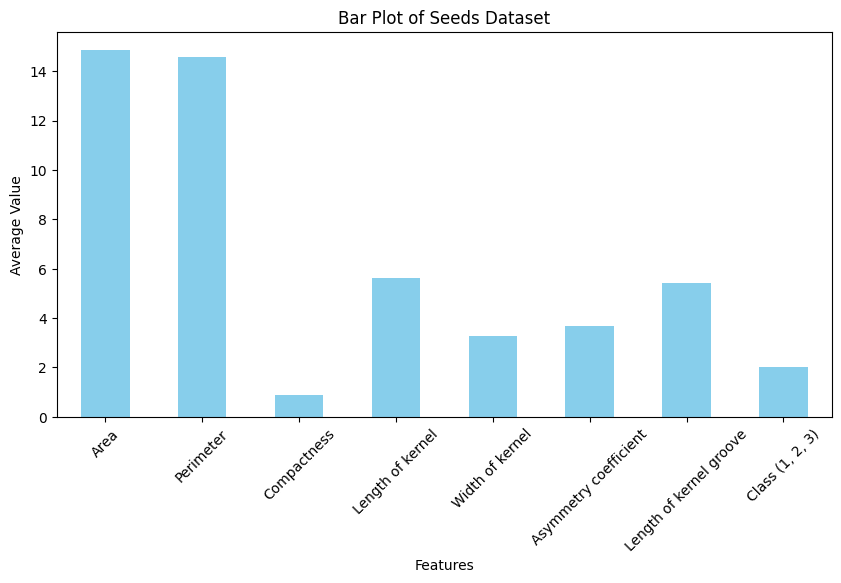

In [ ]:
df.mean(numeric_only=True).plot(
    kind='bar',
    figsize=(10, 5),
    color='skyblue'
)

plt.title('Bar Plot of Seeds Dataset')
plt.xlabel('Features')
plt.ylabel('Average Value')
plt.xticks(rotation=45)
plt.show()

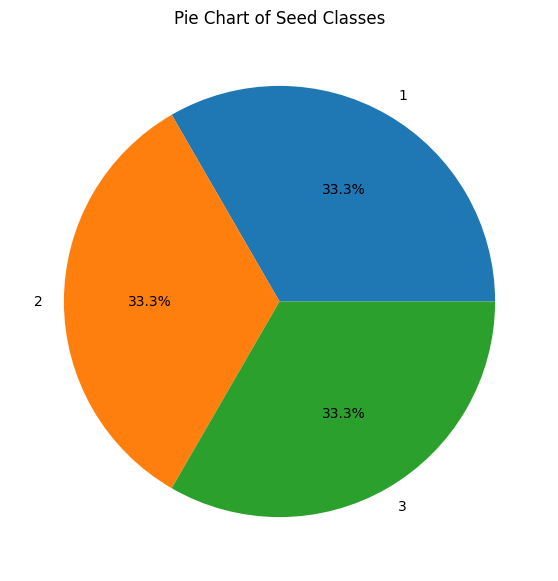

In [ ]:
class_col = df.columns[-1]

df[class_col].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(7, 7)
)

plt.title('Pie Chart of Seed Classes')
plt.ylabel('')
plt.show()

In [ ]:
X=df.drop("Class (1, 2, 3)" ,axis=1)
y_original= df["Class (1, 2, 3)"]

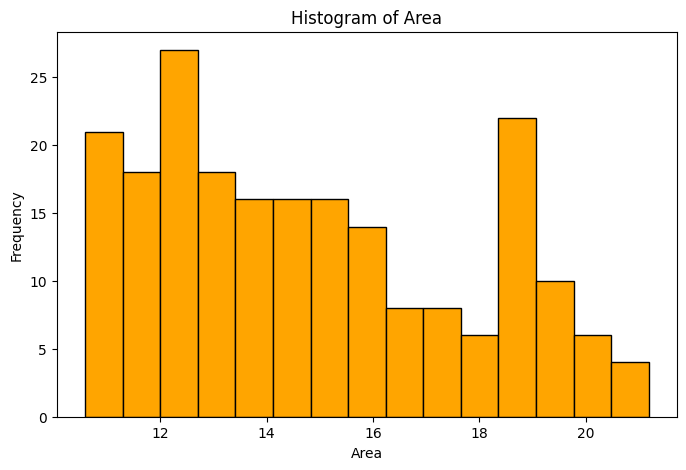

In [ ]:
col = df.select_dtypes(include='number').columns[0]

plt.figure(figsize=(8, 5))
plt.hist(df[col].dropna(), bins=15, color='orange', edgecolor='black')

plt.title(f'Histogram of {col}')
plt.xlabel(col)
plt.ylabel('Frequency')
plt.show()

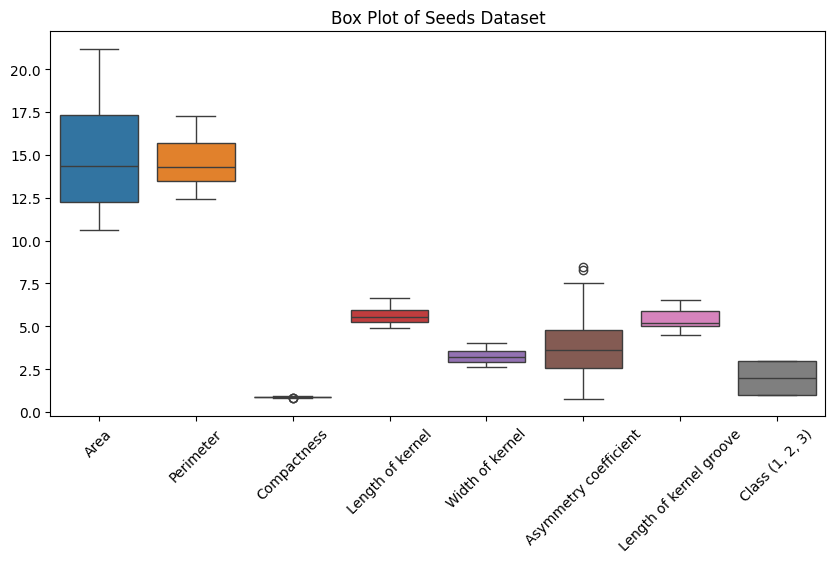

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=df.select_dtypes(include='number'))

plt.title('Box Plot of Seeds Dataset')
plt.xticks(rotation=45)
plt.show()

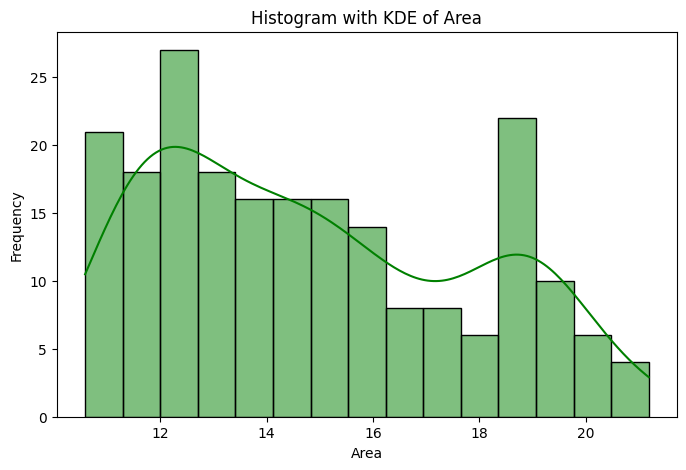

In [ ]:
col = df.select_dtypes(include='number').columns[0]

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x=col,
    kde=True,
    bins=15,
    color='green'
)

plt.title(f'Histogram with KDE of {col}')
plt.xlabel(col)
plt.ylabel('Frequency')
plt.show()

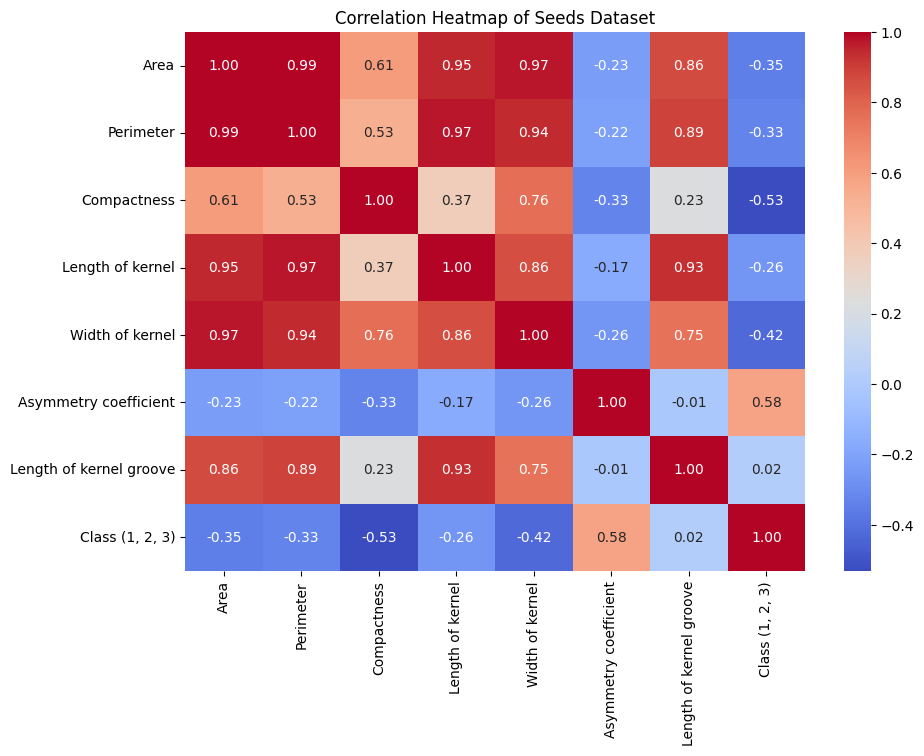

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Seeds Dataset')
plt.show()

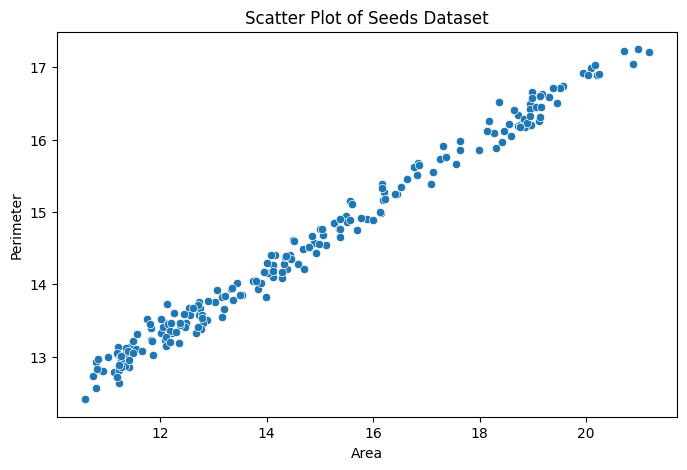

In [ ]:
numeric_cols = df.select_dtypes(include='number').columns

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x=numeric_cols[0],
    y=numeric_cols[1],
    hue=df.columns[-1] if df.columns[-1] not in numeric_cols else None
)

plt.title('Scatter Plot of Seeds Dataset')
plt.xlabel(numeric_cols[0])
plt.ylabel(numeric_cols[1])
plt.show()

In [ ]:
y=y_original-1
print("Original classes:")
print(sorted(y_original.unique()))
print("\nANN encoded classes:")
print(sorted(y.unique()))

Original classes:
[np.int64(1), np.int64(2), np.int64(3)]

ANN encoded classes:
[np.int64(0), np.int64(1), np.int64(2)]


In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("Training samples:",X_train.shape[0])
print("Testing samples:",X_test.shape[0])

Training samples: 168
Testing samples: 42


In [ ]:
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [ ]:
# Use the training-fitted scaler; never refit it on test data.
X_test_scaled[:5]


In [ ]:
model=Sequential([
    Input(shape=(7,)),
    Dense(16,activation="relu"),
    Dense(8,activation="relu"),
    Dense(3,activation="softmax")
])

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 291 (1.14 KB)

 Trainable params: 291 (1.14 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer=Adam(learning_rate=0.001),loss="sparse_categorical_crossentropy",metrics=["accuracy"])

In [ ]:
loss="sparse_categorical_crossentropy"

In [ ]:
early_stop=EarlyStopping(monitor="val_loss",patience=10,restore_best_weights=True)

In [ ]:
history=model.fit(X_train_scaled,y_train,epochs=100,batch_size=16,validation_split=0.2,callbacks=[early_stop],verbose=1)

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.5821 - loss: 0.9476 - val_accuracy: 0.5000 - val_loss: 0.9306
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6045 - loss: 0.8837 - val_accuracy: 0.5000 - val_loss: 0.8707
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6343 - loss: 0.8326 - val_accuracy: 0.5000 - val_loss: 0.8212
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6567 - loss: 0.7905 - val_accuracy: 0.5294 - val_loss: 0.7797
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6940 - loss: 0.7508 - val_accuracy: 0.5294 - val_loss: 0.7458
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7164 - loss: 0.7151 - val_accuracy: 0.6471 - val_loss: 0.7146
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7388 - loss: 0.6840 - val_accuracy: 0.7353 - val_loss: 0.6843
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7761 - loss: 0.6540 - val_accuracy: 0.7353 - val_loss:

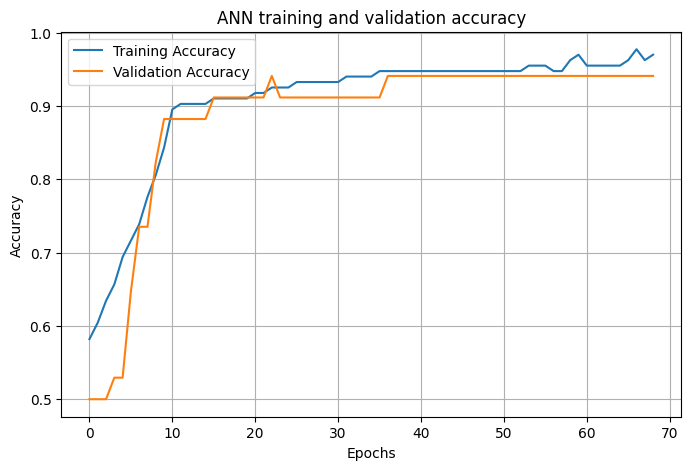

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history["accuracy"],label="Training Accuracy")
plt.plot(history.history["val_accuracy"],label="Validation Accuracy")
plt.title("ANN training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
test_loss,test_accuracy=model.evaluate(X_test_scaled,y_test,verbose=1)
print("Test Loss:",test_loss)
print("Test Accuracy:",test_accuracy)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.8571 - loss: 0.3141
Test Loss: 0.31411856412887573
Test Accuracy: 0.8571428656578064


In [ ]:
y_prob=model.predict(X_test_scaled,verbose=1)
print(y_prob[:5])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
[[9.6632183e-01 7.6446794e-03 2.6033510e-02]
 [3.2052979e-02 1.9993596e-03 9.6594757e-01]
 [7.3059678e-01 2.4182828e-01 2.7574863e-02]
 [1.7276456e-03 4.2813909e-04 9.9784422e-01]
 [1.9356242e-03 9.9805778e-01 6.5707363e-06]]


In [ ]:
y_pred=np.argmax(y_prob,axis=1)
print("Predicted encoded classes")
print(y_pred[:10])

Predicted encoded classes
[0 2 0 2 1 2 1 1 1 1]


In [ ]:
y_pred_original=y_pred+1
y_test_original=y_test+1
print("predicited classes:")
print(y_pred_original[:10])

predicited classes:
[1 3 1 3 2 3 2 2 2 2]


In [ ]:
comparison=pd.DataFrame({"Actual":y_test_original,"Predicted":y_pred_original})
comparison.head(5)

,Actual,Predicted
2,1,1
167,3,3
137,2,1
175,3,3
130,2,2


In [ ]:
accuracy=accuracy_score(y_test_original,y_pred_original)
print("Accuracy:",accuracy)

Accuracy: 0.8571428571428571


In [ ]:
precision=precision_score(y_test_original,y_pred_original,average="weighted")
print("Precision:",precision)

Precision: 0.8625


In [ ]:
recall=recall_score(y_test_original,y_pred_original,average="weighted")
print("Recall:",recall)

Recall: 0.8571428571428571


In [ ]:
f1=f1_score(y_test_original,y_pred_original,average="weighted")
print("F1 Score:",f1)

F1 Score: 0.8500000000000001


In [ ]:
print(classification_report(y_test_original,y_pred_original))

              precision    recall  f1-score   support

           1       0.90      0.64      0.75        14
           2       0.81      0.93      0.87        14
           3       0.88      1.00      0.93        14

    accuracy                           0.86        42
   macro avg       0.86      0.86      0.85        42
weighted avg       0.86      0.86      0.85        42



In [ ]:
cm=confusion_matrix(y_test_original,y_pred_original)
print(cm)

[[ 9  3  2]
 [ 1 13  0]
 [ 0  0 14]]
